# Missing Data & Statistical Inference — Part 1 (Replication Notebook)
### Comparing seven missing-data methods for regression under MCAR, MAR and MNAR

**Author:** Purbasa Bhaduri · M.Sc. Statistics, St. Xavier's University, Kolkata

---

## What this notebook does
A complete dataset of **n = 100** observations is generated from

$$Y = 5 + 2X_1 - 1.5X_2 + X_3 + \varepsilon,\qquad \varepsilon\sim N(0,1)$$

so the **true coefficients** are $\beta_0=5,\ \beta_1=2,\ \beta_2=-1.5,\ \beta_3=1$.
Only **$Y$** is made incomplete; $X_1,X_2,X_3$ stay fully observed. Three missingness mechanisms are imposed on the *same* complete data:

| Mechanism | Rule used in Part 1 |
|---|---|
| **MCAR** | every row has a flat 20% chance of losing $Y$ |
| **MAR** | 30% chance if $X_1<0$, 10% chance if $X_1\ge 0$ (depends on an *observed* variable) |
| **MNAR** | $P(\text{missing})=\text{expit}(-1.3863+0.5\,Y^*)$ where $Y^*$ is standardised $Y$ (depends on the *hidden* value) |

Seven methods are then compared on the main target **$\beta_1$**: Complete Case, Mean Imputation, Hot-Deck, Regression Imputation, Stochastic Regression, MICE (PMM + Rubin's rules) and EM. Uncertainty comes from a 500-replicate bootstrap (MICE uses Rubin's rules).

## How to use it
1. Run **Section 0** (setup) — choose `DATA_SEED` there.
2. Run everything top to bottom (`Runtime → Run all`). Expect roughly 1–3 minutes.
3. Outputs are saved to `results/` and `figures/`.

> **Replication note.** The original Part 1 repository used `np.random.seed(42)`. Here `DATA_SEED` is a setting, so you generate **your own dataset with the same true coefficients**. Set `DATA_SEED = 42` and the notebook reproduces the original numbers (see the check in Section 9).

## Section 0 — Setup and configuration

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# CONFIGURATION  (the only cell you should need to edit)
# ------------------------------------------------------------
DATA_SEED = 42      # seed for YOUR dataset.  Use 42 to reproduce the original repo exactly.
B = 500               # bootstrap replicates (same as Part 1)
BOOT_SEED = 123       # seed for bootstrap resampling (same as Part 1)

os.makedirs("results", exist_ok=True)
os.makedirs("figures", exist_ok=True)

plt.rcParams.update({"figure.dpi": 120, "axes.grid": False})
print("numpy", np.__version__, "| pandas", pd.__version__, "| statsmodels", sm.__version__)

numpy 2.1.3 | pandas 2.2.3 | statsmodels 0.15.0


## Section 1 — Result storage
These two small helpers collect every result so the final tables build themselves.

In [2]:
# ==========================================
# RESULT STORAGE FOR FINAL SUMMARY
# ==========================================

# These dictionaries collect results from the method
# sections so the final tables are built automatically.

master_result_store = {}

def save_master_result(method, mechanism, beta1, se, ci_lower, ci_upper, bias):
    master_result_store[(method, mechanism)] = {
        "Method": method,
        "Mechanism": mechanism,
        "Beta1": beta1,
        "SE": se,
        "CI_Lower": ci_lower,
        "CI_Upper": ci_upper,
        "Bias": bias
    }

point_estimate_store = {}

def save_point_estimates(method, mechanism, params):
    point_estimate_store[(method, mechanism)] = {
        "Method": method,
        "Mechanism": mechanism,
        "Beta0": params["const"],
        "Beta1": params["X1"],
        "Beta2": params["X2"],
        "Beta3": params["X3"]
    }

## Section 2 — Generate the complete data (Step 1)
Three independent standard-normal predictors and normal noise generate $Y$. This is the **ground truth** every method will later be judged against.

In [3]:
# ==========================================
# STEP 1: CREATE COMPLETE MULTIVARIABLE DATA
# ==========================================

import numpy as np
import pandas as pd
import statsmodels.api as sm

from scipy.special import expit

from scipy.stats import t

# Reproducibility (seed set in Section 0)
np.random.seed(DATA_SEED)

# Number of observations
n = 100


# ------------------------------------------
# Generate three predictors
# ------------------------------------------

X1 = np.random.normal(
    loc=0,
    scale=1,
    size=n
)

X2 = np.random.normal(
    loc=0,
    scale=1,
    size=n
)

X3 = np.random.normal(
    loc=0,
    scale=1,
    size=n
)


# ------------------------------------------
# Generate random error
# ------------------------------------------

epsilon = np.random.normal(
    loc=0,
    scale=1,
    size=n
)


# ------------------------------------------
# Generate Y
#
# True model:
# Y = 5 + 2X1 - 1.5X2 + X3 + epsilon
# ------------------------------------------

Y = (
    5
    + 2 * X1
    - 1.5 * X2
    + X3
    + epsilon
)


# ------------------------------------------
# Put everything into one DataFrame
# ------------------------------------------

df = pd.DataFrame({
    "X1": X1,
    "X2": X2,
    "X3": X3,
    "Y": Y
})


print(df.head())

print("\nShape of dataset:", df.shape)

         X1        X2        X3          Y
0  0.496714 -1.415371  0.357787   7.645277
1 -0.138264 -0.420645  0.560785   5.355043
2  0.647689 -0.342715  1.083051   8.639794
3  1.523030 -0.802277  1.053802  10.913648
4 -0.234153 -0.161286 -1.377669   3.375051

Shape of dataset: (100, 4)


## Section 3 — Baseline regression on the complete data (Step 2)
With *no* missing values, OLS should land near the truth. This is the best any method can hope to achieve.

In [4]:
# ==========================================
# STEP 2: BASELINE REGRESSION
# ==========================================

# True coefficients
beta0_true = 5
beta1_true = 2
beta2_true = -1.5
beta3_true = 1


# Predictor matrix
X_model = sm.add_constant(
    df[["X1", "X2", "X3"]]
)


# Create OLS model
model = sm.OLS(
    df["Y"],
    X_model
)


# Fit model
results = model.fit()


# Show regression summary
print(results.summary())


# Extract estimated coefficients
beta_hat = results.params

print("\nEstimated coefficients:")
print(beta_hat)

                            OLS Regression Results                            
Dep. Variable:                      Y   R-squared:                       0.910
Model:                            OLS   Adj. R-squared:                  0.907
Method:                 Least Squares   F-statistic:                     322.1
Date:                Sun, 11 Oct 2026   Prob (F-statistic):           5.85e-50
Time:                        13:14:45   Log-Likelihood:                -127.46
No. Observations:                 100   AIC:                             262.9
Df Residuals:                      96   BIC:                             273.3
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          5.0875      0.089     57.012      0.0

## Section 4 — Impose the three missingness mechanisms (Steps 3–5)
Each mechanism starts again from the **complete** data, and only $Y$ is deleted.

*Order matters for reproducibility:* MCAR, MAR and MNAR draw their random numbers one after the other from the same random stream, exactly as in Part 1.

### 4.1 MCAR — Missing Completely At Random

In [5]:
# ==========================================
# STEP 3: CREATE MCAR
# ==========================================

# Same 20% probability for everybody
missing_prob_mcar = 0.20


# Generate one random number for each row
random_values_mcar = np.random.rand(n)


# True = make Y missing
missing_indicator_mcar = (
    random_values_mcar < missing_prob_mcar
)


# Start from the COMPLETE dataset
df_mcar = df.copy()


# Replace selected Y values with NaN
df_mcar.loc[
    missing_indicator_mcar,
    "Y"
] = np.nan


# Check missingness
print("\n===== MCAR =====")

print(
    "Missing Y values:",
    df_mcar["Y"].isna().sum()
)

print(
    "Missing percentage:",
    df_mcar["Y"].isna().mean() * 100
)


===== MCAR =====
Missing Y values: 25
Missing percentage: 25.0


### 4.2 MAR — Missing At Random (depends on observed $X_1$)

In [6]:
# ==========================================
# STEP 4: CREATE MAR
# ==========================================

# If X1 < 0:
#     30% probability of Y being missing
#
# If X1 >= 0:
#     10% probability of Y being missing

mar_prob = np.where(
    df["X1"] < 0,
    0.30,
    0.10
)


# New random draw for the MAR experiment
random_values_mar = np.random.rand(n)


# Decide which observations become missing
missing_indicator_mar = (
    random_values_mar < mar_prob
)


# Start again from COMPLETE data
df_mar = df.copy()


# Make selected Y values missing
df_mar.loc[
    missing_indicator_mar,
    "Y"
] = np.nan


# Check missingness
print("\n===== MAR =====")

print(
    "Missing Y values:",
    df_mar["Y"].isna().sum()
)

print(
    "Missing percentage:",
    df_mar["Y"].isna().mean() * 100
)


# Verify that missingness is related to X1

mean_x1_observed = (
    df_mar.loc[
        df_mar["Y"].notna(),
        "X1"
    ].mean()
)

mean_x1_missing = (
    df_mar.loc[
        df_mar["Y"].isna(),
        "X1"
    ].mean()
)

print(
    "Mean X1 when Y is observed:",
    mean_x1_observed
)

print(
    "Mean X1 when Y is missing:",
    mean_x1_missing
)


===== MAR =====
Missing Y values: 25
Missing percentage: 25.0
Mean X1 when Y is observed: 0.05522519848762293
Mean X1 when Y is missing: -0.5810616650392442


### 4.3 MNAR — Missing Not At Random (depends on the hidden $Y$)

In [7]:
# ==========================================
# STEP 5: CREATE MNAR
# ==========================================

# Standardize Y first so that the
# missingness mechanism is not too extreme

Y_standardized = (
    (df["Y"] - df["Y"].mean())
    / df["Y"].std()
)


# Probability of missingness depends
# directly on Y
mnar_prob = expit(
    -1.3863 + 0.5 * Y_standardized
)


# New random draw for MNAR
random_values_mnar = np.random.rand(n)


# Decide which observations become missing
missing_indicator_mnar = (
    random_values_mnar < mnar_prob
)


# Start from COMPLETE data
df_mnar = df.copy()


# Hide selected Y values
df_mnar.loc[
    missing_indicator_mnar,
    "Y"
] = np.nan


# Check missingness
print("\n===== MNAR =====")

print(
    "Missing Y values:",
    df_mnar["Y"].isna().sum()
)

print(
    "Missing percentage:",
    df_mnar["Y"].isna().mean() * 100
)


# Verify using the ORIGINAL complete df
# because df_mnar no longer contains
# the missing Y values

mean_y_missing = (
    df.loc[
        missing_indicator_mnar,
        "Y"
    ].mean()
)

mean_y_observed = (
    df.loc[
        ~missing_indicator_mnar,
        "Y"
    ].mean()
)

print(
    "Mean original Y when Y became missing:",
    mean_y_missing
)

print(
    "Mean original Y when Y remained observed:",
    mean_y_observed
)


===== MNAR =====
Missing Y values: 16
Missing percentage: 16.0
Mean original Y when Y became missing: 5.156512754374756
Mean original Y when Y remained observed: 4.887552878255617


In [8]:
# Bundle the three incomplete datasets (used by every method below)
incomplete_data = {"MCAR": df_mcar, "MAR": df_mar, "MNAR": df_mnar}
mechanisms = list(incomplete_data.keys())
FEATURES = ["X1", "X2", "X3"]

beta1_true = 2          # (also defined in Section 3; repeated so this cell is self-contained)

summary_missing = pd.DataFrame({
    "Missing Y": [d["Y"].isna().sum() for d in incomplete_data.values()],
    "Missing %": [d["Y"].isna().mean() * 100 for d in incomplete_data.values()],
}, index=mechanisms)
summary_missing

,Missing Y,Missing %
MCAR,25,25.0
MAR,25,25.0
MNAR,16,16.0


In [11]:
# Download the Generated Original Dataset

df.to_csv("results/complete_data.csv", index=False)
df_mcar.to_csv("results/data_mcar.csv", index=False)
df_mar.to_csv("results/data_mar.csv", index=False)
df_mnar.to_csv("results/data_mnar.csv", index=False)

# Download them to your computer (Colab only)
from google.colab import files
for f in ["complete_data", "data_mcar", "data_mar", "data_mnar"]:
    files.download(f"results/{f}.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Section 5 — Method 1: Complete Case analysis
Delete every row with a missing $Y$, then run ordinary regression on what is left.

**Bootstrap note (important):** the bootstrap resamples **all 100 original rows**, and *then* applies complete-case deletion inside each resample, so the bootstrap reflects the loss of data too.

> *Code change vs. the original repo:* the bootstrap cells there overwrote the variable `df` (the complete dataset). Here the working copy is called `df_inc` so `df` stays the untouched complete data.

### 5.1 MCAR + Complete Case

In [12]:
# ==========================================
# STEP 6A: MCAR + COMPLETE CASE
# ==========================================

df_mcar_cc = df_mcar.dropna()


X_mcar_cc = sm.add_constant(
    df_mcar_cc[["X1", "X2", "X3"]]
)


results_mcar_cc = sm.OLS(
    df_mcar_cc["Y"],
    X_mcar_cc
).fit()


print("\n===== MCAR + COMPLETE CASE =====")

print(
    "Observations:",
    len(df_mcar_cc)
)

print(
    "Estimated coefficients:"
)

print(results_mcar_cc.params)
save_point_estimates("Complete Case", "MCAR", results_mcar_cc.params)


===== MCAR + COMPLETE CASE =====
Observations: 75
Estimated coefficients:
const    4.945459
X1       1.784723
X2      -1.603771
X3       1.019331
dtype: float64


In [13]:
# ============================================
# MCAR: COMPLETE CASE + CORRECTED BOOTSTRAP
# ============================================

df_inc = df_mcar.copy()

# Original complete-case estimate
complete_cases = df_inc.dropna(
    subset=["X1", "X2", "X3", "Y"]
).reset_index(drop=True)

X_original = sm.add_constant(
    complete_cases[["X1", "X2", "X3"]]
)

model_original = sm.OLS(
    complete_cases["Y"],
    X_original
).fit()

beta1_cc = model_original.params["X1"]

# --------------------------------------------
# Bootstrap
# --------------------------------------------

bootstrap_beta1 = []

np.random.seed(BOOT_SEED)

for b in range(B):

    # Resample from ALL original rows
    sample_indices = np.random.choice(
        len(df_inc),
        size=len(df_inc),
        replace=True
    )

    bootstrap_sample = df_inc.iloc[
        sample_indices
    ].reset_index(drop=True)

    # Apply complete-case analysis INSIDE the bootstrap sample
    bootstrap_complete = bootstrap_sample.dropna(
        subset=["X1", "X2", "X3", "Y"]
    )

    # Skip rare bootstrap samples with too few complete observations
    if len(bootstrap_complete) <= 4:
        continue

    X_boot = sm.add_constant(
        bootstrap_complete[["X1", "X2", "X3"]]
    )

    model_boot = sm.OLS(
        bootstrap_complete["Y"],
        X_boot
    ).fit()

    bootstrap_beta1.append(
        model_boot.params["X1"]
    )

bootstrap_beta1 = np.array(bootstrap_beta1)

# Bootstrap inference
se_cc = np.std(
    bootstrap_beta1,
    ddof=1
)

ci_lower = np.percentile(
    bootstrap_beta1,
    2.5
)

ci_upper = np.percentile(
    bootstrap_beta1,
    97.5
)

bias_cc = beta1_cc - beta1_true

print("MCAR Complete Case")
print("beta1 =", beta1_cc)
print("SE =", se_cc)
print("95% CI =", (ci_lower, ci_upper))
print("Bias =", bias_cc)
print("Successful bootstrap samples =", len(bootstrap_beta1))
save_master_result("Complete Case", "MCAR", beta1_cc, se_cc, ci_lower, ci_upper, bias_cc)

MCAR Complete Case
beta1 = 1.7847226108996361
SE = 0.13553333590610614
95% CI = (np.float64(1.5272091458782524), np.float64(2.0247651454461844))
Bias = -0.21527738910036387
Successful bootstrap samples = 500


### 5.2 MAR + Complete Case

In [14]:
# ==========================================
# STEP 6B: MAR + COMPLETE CASE
# ==========================================

df_mar_cc = df_mar.dropna()


X_mar_cc = sm.add_constant(
    df_mar_cc[["X1", "X2", "X3"]]
)


results_mar_cc = sm.OLS(
    df_mar_cc["Y"],
    X_mar_cc
).fit()


print("\n===== MAR + COMPLETE CASE =====")

print(
    "Observations:",
    len(df_mar_cc)
)

print(
    "Estimated coefficients:"
)

print(results_mar_cc.params)
save_point_estimates("Complete Case", "MAR", results_mar_cc.params)


===== MAR + COMPLETE CASE =====
Observations: 75
Estimated coefficients:
const    5.107432
X1       1.776896
X2      -1.571868
X3       0.991216
dtype: float64


In [15]:
# ============================================
# MAR: COMPLETE CASE + CORRECTED BOOTSTRAP
# ============================================

df_inc = df_mar.copy()

# Original complete-case estimate
complete_cases = df_inc.dropna(
    subset=["X1", "X2", "X3", "Y"]
).reset_index(drop=True)

X_original = sm.add_constant(
    complete_cases[["X1", "X2", "X3"]]
)

model_original = sm.OLS(
    complete_cases["Y"],
    X_original
).fit()

beta1_cc = model_original.params["X1"]

# --------------------------------------------
# Bootstrap
# --------------------------------------------

bootstrap_beta1 = []

np.random.seed(BOOT_SEED)

for b in range(B):

    # Resample from ALL original rows
    sample_indices = np.random.choice(
        len(df_inc),
        size=len(df_inc),
        replace=True
    )

    bootstrap_sample = df_inc.iloc[
        sample_indices
    ].reset_index(drop=True)

    # Apply complete-case analysis INSIDE the bootstrap sample
    bootstrap_complete = bootstrap_sample.dropna(
        subset=["X1", "X2", "X3", "Y"]
    )

    # Skip rare bootstrap samples with too few complete observations
    if len(bootstrap_complete) <= 4:
        continue

    X_boot = sm.add_constant(
        bootstrap_complete[["X1", "X2", "X3"]]
    )

    model_boot = sm.OLS(
        bootstrap_complete["Y"],
        X_boot
    ).fit()

    bootstrap_beta1.append(
        model_boot.params["X1"]
    )

bootstrap_beta1 = np.array(bootstrap_beta1)

# Bootstrap inference
se_cc = np.std(
    bootstrap_beta1,
    ddof=1
)

ci_lower = np.percentile(
    bootstrap_beta1,
    2.5
)

ci_upper = np.percentile(
    bootstrap_beta1,
    97.5
)

bias_cc = beta1_cc - beta1_true

print("MAR Complete Case")
print("beta1 =", beta1_cc)
print("SE =", se_cc)
print("95% CI =", (ci_lower, ci_upper))
print("Bias =", bias_cc)
print("Successful bootstrap samples =", len(bootstrap_beta1))
save_master_result("Complete Case", "MAR", beta1_cc, se_cc, ci_lower, ci_upper, bias_cc)

MAR Complete Case
beta1 = 1.7768964817621882
SE = 0.13603742501551958
95% CI = (np.float64(1.532446588100685), np.float64(2.0554792572194347))
Bias = -0.22310351823781183
Successful bootstrap samples = 500


### 5.3 MNAR + Complete Case

In [16]:
# ==========================================
# STEP 6C: MNAR + COMPLETE CASE
# ==========================================

df_mnar_cc = df_mnar.dropna()


X_mnar_cc = sm.add_constant(
    df_mnar_cc[["X1", "X2", "X3"]]
)


results_mnar_cc = sm.OLS(
    df_mnar_cc["Y"],
    X_mnar_cc
).fit()


print("\n===== MNAR + COMPLETE CASE =====")

print(
    "Observations:",
    len(df_mnar_cc)
)

print(
    "Estimated coefficients:"
)

print(results_mnar_cc.params)
save_point_estimates("Complete Case", "MNAR", results_mnar_cc.params)


===== MNAR + COMPLETE CASE =====
Observations: 84
Estimated coefficients:
const    5.115116
X1       1.748686
X2      -1.549276
X3       0.976194
dtype: float64


In [17]:
# ============================================
# MNAR: COMPLETE CASE + CORRECTED BOOTSTRAP
# ============================================

df_inc = df_mnar.copy()

# Original complete-case estimate
complete_cases = df_inc.dropna(
    subset=["X1", "X2", "X3", "Y"]
).reset_index(drop=True)

X_original = sm.add_constant(
    complete_cases[["X1", "X2", "X3"]]
)

model_original = sm.OLS(
    complete_cases["Y"],
    X_original
).fit()

beta1_cc = model_original.params["X1"]

# --------------------------------------------
# Bootstrap
# --------------------------------------------

bootstrap_beta1 = []

np.random.seed(BOOT_SEED)

for b in range(B):

    # Resample from ALL original rows
    sample_indices = np.random.choice(
        len(df_inc),
        size=len(df_inc),
        replace=True
    )

    bootstrap_sample = df_inc.iloc[
        sample_indices
    ].reset_index(drop=True)

    # Apply complete-case analysis INSIDE the bootstrap sample
    bootstrap_complete = bootstrap_sample.dropna(
        subset=["X1", "X2", "X3", "Y"]
    )

    # Skip rare bootstrap samples with too few complete observations
    if len(bootstrap_complete) <= 4:
        continue

    X_boot = sm.add_constant(
        bootstrap_complete[["X1", "X2", "X3"]]
    )

    model_boot = sm.OLS(
        bootstrap_complete["Y"],
        X_boot
    ).fit()

    bootstrap_beta1.append(
        model_boot.params["X1"]
    )

bootstrap_beta1 = np.array(bootstrap_beta1)

# Bootstrap inference
se_cc = np.std(
    bootstrap_beta1,
    ddof=1
)

ci_lower = np.percentile(
    bootstrap_beta1,
    2.5
)

ci_upper = np.percentile(
    bootstrap_beta1,
    97.5
)

bias_cc = beta1_cc - beta1_true

print("MNAR Complete Case")
print("beta1 =", beta1_cc)
print("SE =", se_cc)
print("95% CI =", (ci_lower, ci_upper))
print("Bias =", bias_cc)
print("Successful bootstrap samples =", len(bootstrap_beta1))
save_master_result("Complete Case", "MNAR", beta1_cc, se_cc, ci_lower, ci_upper, bias_cc)

MNAR Complete Case
beta1 = 1.7486858337955549
SE = 0.1219569274735909
95% CI = (np.float64(1.5008796538689382), np.float64(1.981103279238143))
Bias = -0.25131416620444513
Successful bootstrap samples = 500


## Section 6 — Toolbox for the remaining six methods
The original notebook (the copy in the repo ends inside the MNAR complete-case bootstrap) implemented the remaining methods exactly as described in the Part 1 study guide. They are rebuilt here as small reusable functions, so **one bootstrap engine** serves them all.

Every imputer takes an incomplete DataFrame and returns a **completed** DataFrame; the engine then fits OLS on it. This guarantees each method is judged by the same rules.

In [18]:
# ------------------------------------------------------------
# Generic helpers
# ------------------------------------------------------------
def fit_ols(data):
    """OLS of Y on X1, X2, X3 (with intercept). Returns the fitted statsmodels result."""
    X = sm.add_constant(data[FEATURES], has_constant="add")
    return sm.OLS(data["Y"], X).fit()


def bootstrap_inference(df_inc, estimator, B=B, seed=BOOT_SEED, min_obs=5):
    """
    Part 1 bootstrap scheme:
      1. resample ALL rows with replacement,
      2. run the WHOLE method (imputation + regression) inside the resample,
      3. keep beta1.
    SE = sd of the B estimates, CI = 2.5th / 97.5th percentiles.
    `estimator(sample)` must return beta1 for that resample.
    """
    np.random.seed(seed)
    draws = []
    for _ in range(B):
        idx = np.random.choice(len(df_inc), size=len(df_inc), replace=True)
        sample = df_inc.iloc[idx].reset_index(drop=True)
        if sample["Y"].notna().sum() < min_obs:
            continue
        draws.append(estimator(sample))
    draws = np.array(draws)
    return np.std(draws, ddof=1), np.percentile(draws, 2.5), np.percentile(draws, 97.5), len(draws)


# ------------------------------------------------------------
# Imputers (each returns a COMPLETED copy of the data)
# ------------------------------------------------------------
def impute_mean(data):
    """Replace every missing Y by the mean of the observed Y."""
    out = data.copy()
    out["Y"] = out["Y"].fillna(out["Y"].mean())
    return out


def impute_hotdeck(data):
    """
    Deterministic nearest-neighbour hot-deck (as in Part 1):
    for each missing row find the observed row with the smallest squared Euclidean
    distance on (X1, X2, X3) and copy that donor's actual Y.
    """
    out = data.reset_index(drop=True).copy()
    miss = out["Y"].isna().values
    X_obs = out.loc[~miss, FEATURES].values
    y_obs = out.loc[~miss, "Y"].values
    X_mis = out.loc[miss, FEATURES].values
    dist2 = ((X_mis[:, None, :] - X_obs[None, :, :]) ** 2).sum(axis=2)
    out.loc[miss, "Y"] = y_obs[dist2.argmin(axis=1)]
    return out


def impute_regression(data):
    """Fit Y ~ X on observed rows, then drop the PREDICTIONS into the holes."""
    out = data.copy()
    miss = out["Y"].isna()
    fit = fit_ols(out[~miss])
    X_mis = sm.add_constant(out.loc[miss, FEATURES], has_constant="add")
    out.loc[miss, "Y"] = fit.predict(X_mis)
    return out


def impute_stochastic(data):
    """Regression imputation + a residual resampled (with replacement) from the observed fit.
    Uses numpy's GLOBAL random stream, exactly like Part 1."""
    out = data.copy()
    miss = out["Y"].isna()
    fit = fit_ols(out[~miss])
    X_mis = sm.add_constant(out.loc[miss, FEATURES], has_constant="add")
    noise = np.random.choice(fit.resid.values, size=int(miss.sum()), replace=True)
    out.loc[miss, "Y"] = fit.predict(X_mis).values + noise
    return out


# ------------------------------------------------------------
# EM for a normal linear regression with Y partially missing
# ------------------------------------------------------------
def em_regression(data, tol=1e-8, max_iter=1000):
    """
    EM for  Y = X beta + e,  e ~ N(0, sigma^2),  X fully observed, Y partly missing.
      E-step : E[Y_i]   = x_i' beta           (missing rows)
               E[Y_i^2] = (x_i' beta)^2 + sigma^2
      M-step : beta   = (X'X)^-1 X' E[Y]
               sigma2 = mean( E[Y^2] - 2 E[Y] x'beta + (x'beta)^2 )
    Start: beta = (0,0,0,0), sigma2 = variance of observed Y (deliberately poor start).
    Stop when the largest parameter change is < tol.
    Returns beta, sigma2, iterations, history of beta1.
    """
    X = sm.add_constant(data[FEATURES]).values
    y = data["Y"].values
    miss = np.isnan(y)
    beta = np.zeros(X.shape[1])
    sigma2 = np.var(y[~miss], ddof=1)
    history = []
    for it in range(1, max_iter + 1):
        mu = X @ beta
        Ey = np.where(miss, mu, y)
        Ey2 = np.where(miss, mu ** 2 + sigma2, y ** 2)
        beta_new = np.linalg.solve(X.T @ X, X.T @ Ey)
        mu_new = X @ beta_new
        sigma2_new = np.mean(Ey2 - 2 * Ey * mu_new + mu_new ** 2)
        history.append(beta_new[1])
        change = max(np.max(np.abs(beta_new - beta)), abs(sigma2_new - sigma2))
        beta, sigma2 = beta_new, sigma2_new
        if change < tol:
            break
    return beta, sigma2, it, history


# ------------------------------------------------------------
# MICE with PMM — faithful to the Part 1 implementation
# ------------------------------------------------------------
def mice_pmm_part1(data, m=5, n_cycles=5, k=5, seed_base=1000):
    """
    Part 1 version: m = 5 completed datasets, 5 cycles each, k = 5 PMM donors.
      - start by filling missing Y with the observed mean,
      - regress ORIGINAL observed Y on X,  predict for every row,
      - for each missing row take the k observed rows with closest predictions,
        pick one at random, copy its ACTUAL Y,
      - fit the final regression, store beta1 and its variance.
    Known limitation (documented in the study guide): only Y is incomplete, so the model never
    changes between cycles and the generator is re-seeded each cycle; the cycles add nothing.
    Part 2 replaces this with a proper chained-equations loop.
    """
    data = data.reset_index(drop=True)
    obs = data["Y"].notna().values
    X_all = sm.add_constant(data[FEATURES]).values
    obs_idx = np.where(obs)[0]
    betas, variances = [], []
    for j in range(m):
        y_work = data["Y"].fillna(data["Y"].mean()).values.copy()
        for _ in range(n_cycles):
            rng = np.random.default_rng(seed_base + j)        # re-created each cycle (as in Part 1)
            fit = sm.OLS(data["Y"].values[obs], X_all[obs]).fit()
            pred = X_all @ fit.params
            for i in np.where(~obs)[0]:
                nearest = obs_idx[np.argsort(np.abs(pred[obs_idx] - pred[i]))[:k]]
                y_work[i] = data["Y"].values[rng.choice(nearest)]
        final = sm.OLS(y_work, X_all).fit()
        betas.append(final.params[1])
        variances.append(final.bse[1] ** 2)
    return np.array(betas), np.array(variances)


from scipy.stats import t as t_dist

def rubin_pool(estimates, variances, level=0.95):
    """Rubin's rules:  T = W + (1 + 1/m) B,   t-interval with Rubin's degrees of freedom."""
    m = len(estimates)
    q_bar = estimates.mean()
    W = variances.mean()                    # within-imputation variance
    Bv = estimates.var(ddof=1)              # between-imputation variance
    T = W + (1 + 1 / m) * Bv
    se = np.sqrt(T)
    df_rubin = (m - 1) * (1 + W / ((1 + 1 / m) * Bv)) ** 2 if Bv > 0 else np.inf
    tcrit = t_dist.ppf(1 - (1 - level) / 2, df_rubin)
    return {"q_bar": q_bar, "W": W, "B": Bv, "T": T, "SE": se, "df": df_rubin,
            "CI_Lower": q_bar - tcrit * se, "CI_Upper": q_bar + tcrit * se}


def run_imputation_method(method_name, imputer, point_seed=42):
    """Run one single-imputation method across MCAR / MAR / MNAR and store the results."""
    rows = []
    for mech in mechanisms:
        d = incomplete_data[mech]

        # point estimate (point_seed only matters for methods with randomness)
        np.random.seed(point_seed)
        fit = fit_ols(imputer(d))
        beta1 = fit.params["X1"]
        save_point_estimates(method_name, mech, fit.params)

        # bootstrap: the whole method is re-run inside every resample
        se, lo, hi, n_ok = bootstrap_inference(d, lambda s: fit_ols(imputer(s)).params["X1"])
        bias = beta1 - beta1_true
        save_master_result(method_name, mech, beta1, se, lo, hi, bias)
        rows.append({"Mechanism": mech, "Beta1": beta1, "SE": se, "CI_Lower": lo, "CI_Upper": hi,
                     "Bias": bias, "Bootstrap samples": n_ok})
    return pd.DataFrame(rows).set_index("Mechanism")

print("Toolbox ready.")

Toolbox ready.


## Section 7 — Methods 2–7

### Method 2 — Mean imputation
Every missing $Y$ gets the *same* number: the mean of the observed $Y$. The completed data then show artificially little variation and a weakened $X_1$–$Y$ relationship, so $\hat\beta_1$ is pulled towards 0.

In [19]:
res_mean = run_imputation_method("Mean Imputation", impute_mean)
res_mean.round(4)

,Beta1,SE,CI_Lower,CI_Upper,Bias,Bootstrap samples
Mechanism,,,,,,
MCAR,1.0887,0.2285,0.6490,1.5650,-0.9113,500
MAR,1.3066,0.1864,0.9153,1.6594,-0.6934,500
MNAR,1.4127,0.1699,1.0472,1.7020,-0.5873,500


### Method 3 — Hot-deck imputation (nearest donor)
For each missing row, find the observed row whose $(X_1,X_2,X_3)$ is closest (squared Euclidean distance) and **copy that donor's real $Y$**. Real observed values preserve the scale of $Y$. *This implementation is deterministic* — no random donor choice.

In [20]:
res_hd = run_imputation_method("Hot-Deck", impute_hotdeck)
res_hd.round(4)

,Beta1,SE,CI_Lower,CI_Upper,Bias,Bootstrap samples
Mechanism,,,,,,
MCAR,1.6583,0.1654,1.2618,1.9184,-0.3417,500
MAR,1.7872,0.1480,1.4164,1.9961,-0.2128,500
MNAR,1.7222,0.1234,1.4686,1.9536,-0.2778,500


### Method 4 — Regression imputation
Fit $Y=\beta_0+\beta_1X_1+\beta_2X_2+\beta_3X_3+\varepsilon$ on the observed rows and fill each hole with its **prediction**. The imputed points sit exactly on the fitted plane, so the final coefficients equal the observed-case regression (identical to Complete Case here). What it *loses* is the residual scatter, so uncertainty is understated.

In [21]:
res_reg = run_imputation_method("Regression Imputation", impute_regression)
res_reg.round(4)

,Beta1,SE,CI_Lower,CI_Upper,Bias,Bootstrap samples
Mechanism,,,,,,
MCAR,1.7847,0.1355,1.5272,2.0248,-0.2153,500
MAR,1.7769,0.1360,1.5324,2.0555,-0.2231,500
MNAR,1.7487,0.1220,1.5009,1.9811,-0.2513,500


### Method 5 — Stochastic regression imputation
Same as regression imputation, but each prediction gets a **residual resampled from the observed fit**, restoring natural scatter. Because residuals are drawn at random, two runs give different completed datasets.

In [22]:
res_sr = run_imputation_method("Stochastic Regression", impute_stochastic, point_seed=42)
res_sr.round(4)

,Beta1,SE,CI_Lower,CI_Upper,Bias,Bootstrap samples
Mechanism,,,,,,
MCAR,1.7065,0.1397,1.4873,2.0459,-0.2935,500
MAR,1.7591,0.1474,1.4989,2.0648,-0.2409,500
MNAR,1.7193,0.1243,1.5175,1.9870,-0.2807,500


### Method 6 — MICE with predictive mean matching (PMM), pooled by Rubin's rules
Five completed datasets are created; in each, a missing $Y$ is replaced by the **actual observed $Y$ of a randomly chosen donor among the 5 observed cases with the closest predicted value**. Each completed dataset gives its own $\hat\beta_1$; Rubin's rules combine them:

$$\bar Q=\frac1m\sum \hat\beta_1^{(j)},\quad W=\frac1m\sum \widehat{\mathrm{Var}}^{(j)},\quad B=\frac1{m-1}\sum(\hat\beta_1^{(j)}-\bar Q)^2,\quad T=W+\Big(1+\frac1m\Big)B$$

and $SE=\sqrt T$. The interval uses a $t$ distribution with Rubin's degrees of freedom. **No bootstrap is used for MICE.**

In [23]:
mice_rows, mice_detail = [], []
mice_seed_bases = {"MCAR": 1000, "MAR": 2000, "MNAR": 3000}   # different seeds per mechanism

for mech in mechanisms:
    betas, variances = mice_pmm_part1(incomplete_data[mech], seed_base=mice_seed_bases[mech])
    pooled = rubin_pool(betas, variances)
    bias = pooled["q_bar"] - beta1_true

    save_master_result("MICE", mech, pooled["q_bar"], pooled["SE"], pooled["CI_Lower"], pooled["CI_Upper"], bias)

    # point estimates of all 4 coefficients (pooled across the 5 completed sets is not stored in Part 1;
    # we store the beta1 pooled value and leave other coefficients for the 'Beta1' view only)
    mice_rows.append({"Mechanism": mech, "Beta1": pooled["q_bar"], "SE": pooled["SE"],
                      "CI_Lower": pooled["CI_Lower"], "CI_Upper": pooled["CI_Upper"], "Bias": bias})
    mice_detail.append({"Mechanism": mech,
                        **{f"Imputation_{i+1}": b for i, b in enumerate(betas)},
                        "Pooled_Beta1": pooled["q_bar"], "Within_Variance": pooled["W"],
                        "Between_Variance": pooled["B"], "Pooled_SE": pooled["SE"], "Rubin_df": pooled["df"]})

res_mice = pd.DataFrame(mice_rows).set_index("Mechanism")
mice_details = pd.DataFrame(mice_detail).set_index("Mechanism")
display(res_mice.round(4))
display(mice_details.round(6))

,Beta1,SE,CI_Lower,CI_Upper,Bias
Mechanism,,,,,
MCAR,1.6593,0.1142,1.4333,1.8852,-0.3407
MAR,1.7837,0.0954,1.5964,1.9711,-0.2163
MNAR,1.7421,0.1119,1.5208,1.9633,-0.2579


,Imputation_1,Imputation_2,Imputation_3,Imputation_4,Imputation_5,Pooled_Beta1,Within_Variance,Between_Variance,Pooled_SE,Rubin_df
Mechanism,,,,,,,,,,
MCAR,1.678706,1.645220,1.607999,1.640728,1.723652,1.659261,0.010727,0.001923,0.114170,127.604389
MAR,1.764651,1.750434,1.802646,1.803065,1.797901,1.783739,0.008384,0.000601,0.095421,636.983593
MNAR,1.754155,1.722283,1.793265,1.758682,1.681915,1.742060,0.010405,0.001763,0.111899,140.075880


### Method 7 — EM algorithm
EM does not literally fill in values. Each iteration alternates:

* **E-step** — replace each missing $Y_i$ by its conditional expectation $x_i^\top\beta$ (and $Y_i^2$ by $(x_i^\top\beta)^2+\sigma^2$);
* **M-step** — re-estimate $\beta,\sigma^2$ as if those expectations were data.

It starts from deliberately poor values $\beta^{(0)}=(0,0,0,0)$ and stops once parameters change by less than $10^{-8}$. Inference uses the same 500-sample bootstrap.

> With only $Y$ missing and an **ignorable-missingness** model (no model for the missingness itself), EM converges to the same coefficients as Complete Case / Regression imputation. That is a feature of this special setup, not a general theorem.

In [24]:
em_rows, em_paths, em_iters = [], {}, {}

for mech in mechanisms:
    d = incomplete_data[mech]
    beta_hat, sigma2_hat, n_iter, path = em_regression(d)
    em_paths[mech], em_iters[mech] = path, n_iter
    save_point_estimates("EM", mech, {"const": beta_hat[0], "X1": beta_hat[1], "X2": beta_hat[2], "X3": beta_hat[3]})

    se, lo, hi, n_ok = bootstrap_inference(d, lambda s: em_regression(s)[0][1])
    bias = beta_hat[1] - beta1_true
    save_master_result("EM", mech, beta_hat[1], se, lo, hi, bias)
    em_rows.append({"Mechanism": mech, "Beta1": beta_hat[1], "SE": se, "CI_Lower": lo, "CI_Upper": hi,
                    "Bias": bias, "Iterations": n_iter})

res_em = pd.DataFrame(em_rows).set_index("Mechanism")
res_em.round(4)

,Beta1,SE,CI_Lower,CI_Upper,Bias,Iterations
Mechanism,,,,,,
MCAR,1.7847,0.1355,1.5272,2.0248,-0.2153,20
MAR,1.7769,0.1360,1.5324,2.0555,-0.2231,20
MNAR,1.7487,0.1220,1.5009,1.9811,-0.2513,14


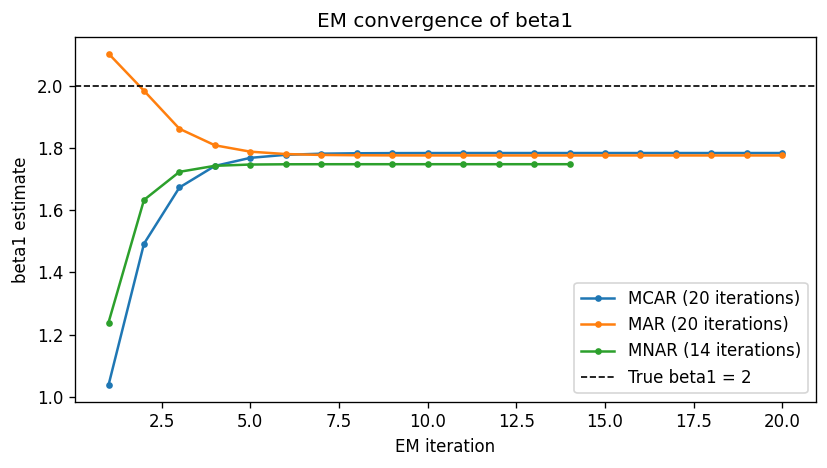

In [25]:
# EM convergence plot
fig, ax = plt.subplots(figsize=(7, 4))
for mech in mechanisms:
    ax.plot(range(1, len(em_paths[mech]) + 1), em_paths[mech], marker="o", ms=3, label=f"{mech} ({em_iters[mech]} iterations)")
ax.axhline(beta1_true, color="k", ls="--", lw=1, label="True beta1 = 2")
ax.set_xlabel("EM iteration"); ax.set_ylabel("beta1 estimate"); ax.set_title("EM convergence of beta1")
ax.legend(); plt.tight_layout()
plt.savefig("figures/em_convergence_beta1.png", dpi=200); plt.show()

## Section 8 — Master results

Everything collected in the result stores is assembled into one tidy table.

In [26]:
method_order = ["Complete Case", "Mean Imputation", "Hot-Deck", "Regression Imputation",
                "Stochastic Regression", "MICE", "EM"]

master_results = (pd.DataFrame(master_result_store.values())
                    .assign(Absolute_Bias=lambda x: x["Bias"].abs()))
master_results["Method"] = pd.Categorical(master_results["Method"], method_order, ordered=True)
master_results["Mechanism"] = pd.Categorical(master_results["Mechanism"], mechanisms, ordered=True)
master_results = master_results.sort_values(["Mechanism", "Method"]).reset_index(drop=True)

master_results.round(4)

,Method,Mechanism,Beta1,SE,CI_Lower,CI_Upper,Bias,Absolute_Bias
0,Complete Case,MCAR,1.7847,0.1355,1.5272,2.0248,-0.2153,0.2153
1,Mean Imputation,MCAR,1.0887,0.2285,0.6490,1.5650,-0.9113,0.9113
2,Hot-Deck,MCAR,1.6583,0.1654,1.2618,1.9184,-0.3417,0.3417
3,Regression Imputation,MCAR,1.7847,0.1355,1.5272,2.0248,-0.2153,0.2153
4,Stochastic Regression,MCAR,1.7065,0.1397,1.4873,2.0459,-0.2935,0.2935
5,MICE,MCAR,1.6593,0.1142,1.4333,1.8852,-0.3407,0.3407
6,EM,MCAR,1.7847,0.1355,1.5272,2.0248,-0.2153,0.2153
7,Complete Case,MAR,1.7769,0.1360,1.5324,2.0555,-0.2231,0.2231
8,Mean Imputation,MAR,1.3066,0.1864,0.9153,1.6594,-0.6934,0.6934
9,Hot-Deck,MAR,1.7872,0.1480,1.4164,1.9961,-0.2128,0.2128


In [27]:
# Compact pivot views
display(master_results.pivot(index="Method", columns="Mechanism", values="Beta1").round(3).rename_axis(columns="beta1-hat"))
display(master_results.pivot(index="Method", columns="Mechanism", values="Bias").round(3).rename_axis(columns="bias"))
display(master_results.pivot(index="Method", columns="Mechanism", values="SE").round(3).rename_axis(columns="SE"))

# All four coefficients for the single-imputation methods and EM
point_estimates = pd.DataFrame(point_estimate_store.values())
point_estimates.round(3)

beta1-hat,MCAR,MAR,MNAR
Method,,,
Complete Case,1.785,1.777,1.749
Mean Imputation,1.089,1.307,1.413
Hot-Deck,1.658,1.787,1.722
Regression Imputation,1.785,1.777,1.749
Stochastic Regression,1.706,1.759,1.719
MICE,1.659,1.784,1.742
EM,1.785,1.777,1.749


bias,MCAR,MAR,MNAR
Method,,,
Complete Case,-0.215,-0.223,-0.251
Mean Imputation,-0.911,-0.693,-0.587
Hot-Deck,-0.342,-0.213,-0.278
Regression Imputation,-0.215,-0.223,-0.251
Stochastic Regression,-0.294,-0.241,-0.281
MICE,-0.341,-0.216,-0.258
EM,-0.215,-0.223,-0.251


SE,MCAR,MAR,MNAR
Method,,,
Complete Case,0.136,0.136,0.122
Mean Imputation,0.229,0.186,0.170
Hot-Deck,0.165,0.148,0.123
Regression Imputation,0.136,0.136,0.122
Stochastic Regression,0.140,0.147,0.124
MICE,0.114,0.095,0.112
EM,0.136,0.136,0.122


,Method,Mechanism,Beta0,Beta1,Beta2,Beta3
0,Complete Case,MCAR,4.945,1.785,-1.604,1.019
1,Complete Case,MAR,5.107,1.777,-1.572,0.991
2,Complete Case,MNAR,5.115,1.749,-1.549,0.976
3,Mean Imputation,MCAR,4.987,1.089,-1.360,0.758
4,Mean Imputation,MAR,5.364,1.307,-1.294,0.837
5,Mean Imputation,MNAR,5.014,1.413,-1.304,0.753
6,Hot-Deck,MCAR,4.981,1.658,-1.594,0.915
7,Hot-Deck,MAR,5.124,1.787,-1.522,0.954
8,Hot-Deck,MNAR,5.049,1.722,-1.480,0.934
9,Regression Imputation,MCAR,4.945,1.785,-1.604,1.019


In [28]:
master_results.to_csv("results/master_results.csv", index=False)
mice_details.to_csv("results/mice_details.csv")
point_estimates.to_csv("results/point_estimates_all_coefficients.csv", index=False)
print("Saved: results/master_results.csv, results/mice_details.csv, results/point_estimates_all_coefficients.csv")

Saved: results/master_results.csv, results/mice_details.csv, results/point_estimates_all_coefficients.csv


### Figures

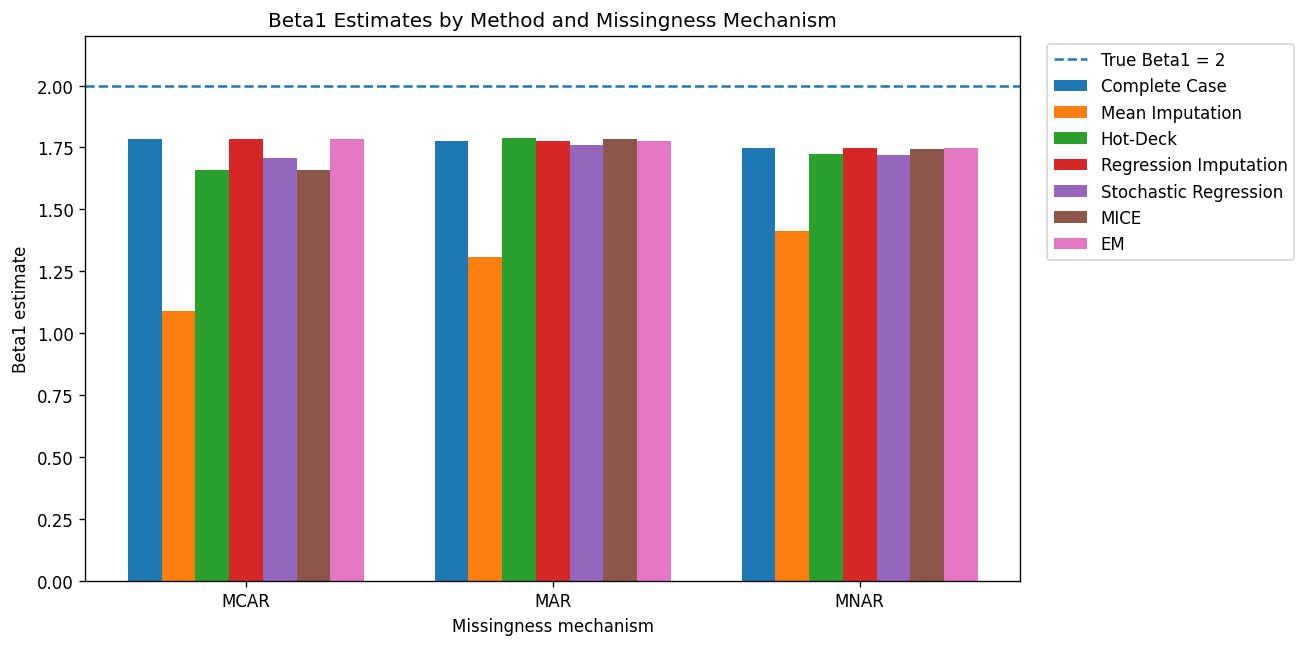

In [29]:
colors = dict(zip(method_order, plt.cm.tab10(np.arange(7))))

# 1) Overall comparison of beta1 by method and mechanism
fig, ax = plt.subplots(figsize=(11, 5.5))
width = 0.11
x = np.arange(len(mechanisms))
for i, meth in enumerate(method_order):
    vals = [master_results.query("Method == @meth and Mechanism == @m")["Beta1"].iloc[0] for m in mechanisms]
    ax.bar(x + (i - 3) * width, vals, width, label=meth, color=colors[meth])
ax.axhline(beta1_true, ls="--", lw=1.5, color="tab:blue", label="True Beta1 = 2")
ax.set_xticks(x); ax.set_xticklabels(mechanisms)
ax.set_xlabel("Missingness mechanism"); ax.set_ylabel("Beta1 estimate")
ax.set_title("Beta1 Estimates by Method and Missingness Mechanism")
ax.set_ylim(0, 2.2); ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout(); plt.savefig("figures/beta1_estimates_by_mechanism.png", dpi=200); plt.show()

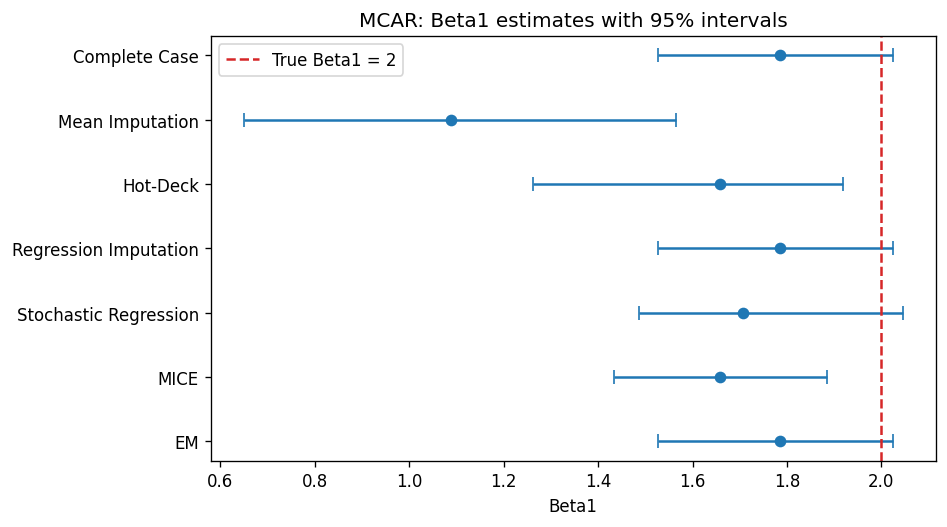

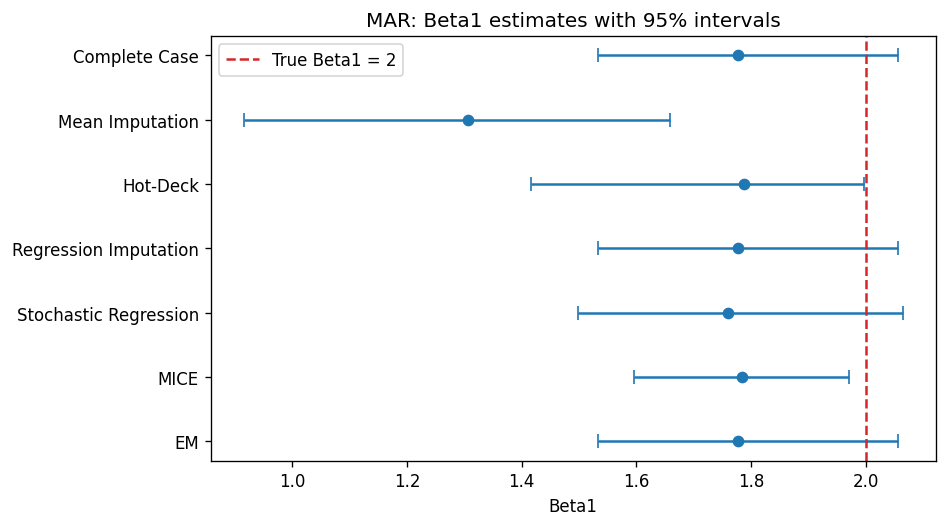

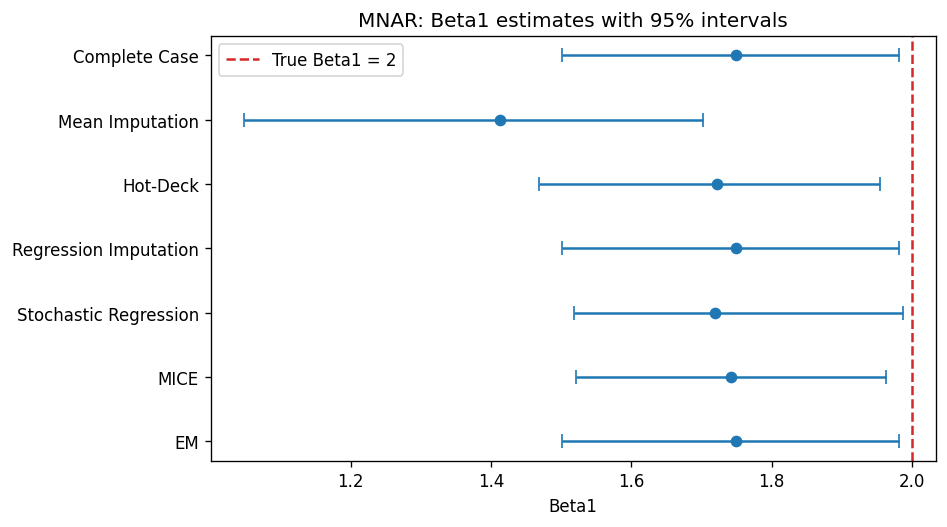

In [30]:
# 2) 95% intervals, one figure per mechanism
for mech in mechanisms:
    sub = master_results.query("Mechanism == @mech").set_index("Method").loc[method_order]
    fig, ax = plt.subplots(figsize=(8, 4.5))
    y = np.arange(len(sub))[::-1]
    ax.errorbar(sub["Beta1"], y, xerr=[sub["Beta1"] - sub["CI_Lower"], sub["CI_Upper"] - sub["Beta1"]],
                fmt="o", capsize=4, color="tab:blue")
    ax.axvline(beta1_true, ls="--", color="tab:red", label="True Beta1 = 2")
    ax.set_yticks(y); ax.set_yticklabels(sub.index)
    ax.set_xlabel("Beta1"); ax.set_title(f"{mech}: Beta1 estimates with 95% intervals"); ax.legend()
    plt.tight_layout(); plt.savefig(f"figures/beta1_ci_{mech.lower()}.png", dpi=200); plt.show()

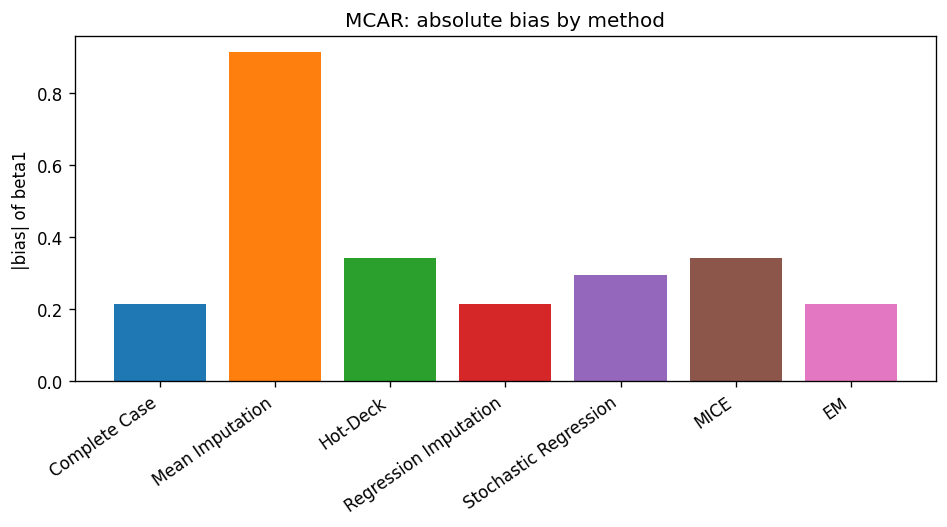

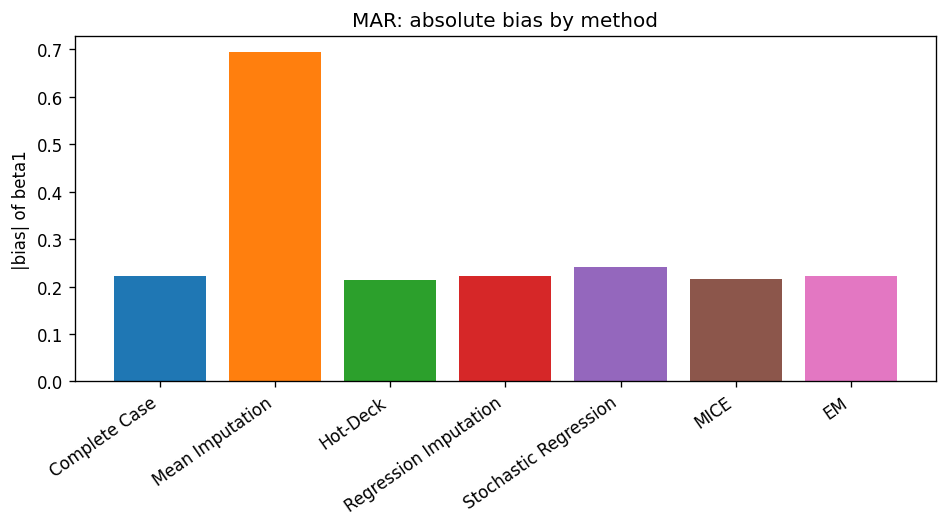

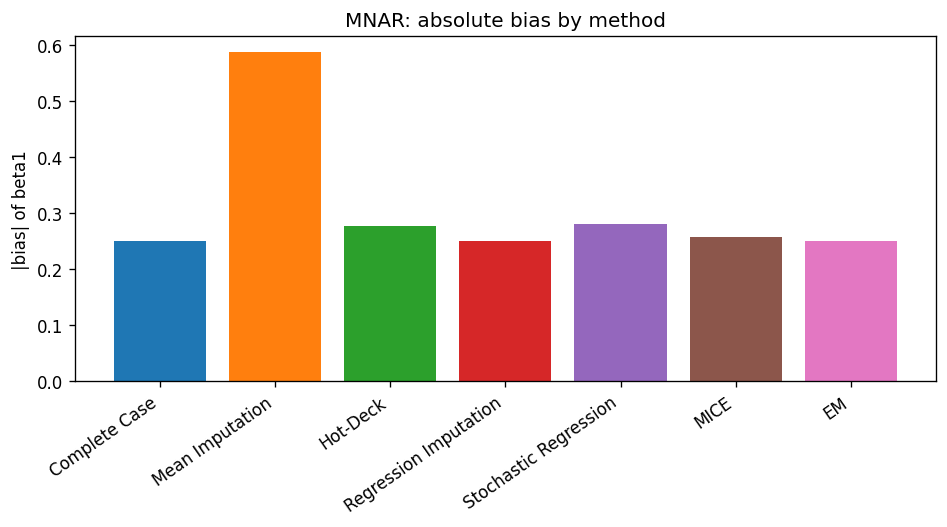

In [31]:
# 3) Absolute bias, one figure per mechanism
for mech in mechanisms:
    sub = master_results.query("Mechanism == @mech").set_index("Method").loc[method_order]
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.bar(sub.index, sub["Absolute_Bias"], color=[colors[m] for m in sub.index])
    ax.set_ylabel("|bias| of beta1"); ax.set_title(f"{mech}: absolute bias by method")
    plt.xticks(rotation=35, ha="right"); plt.tight_layout()
    plt.savefig(f"figures/beta1_absolute_bias_{mech.lower()}.png", dpi=200); plt.show()

## Section 9 — Replication check against the original Part 1 results
If you set `DATA_SEED = 42`, this notebook should reproduce the original repository's numbers. The cell below compares the two. (With any other seed it simply tells you the check is skipped — your dataset is different by design.)

**What to expect at seed 42:** Complete Case, Mean, Hot-Deck, Regression, Stochastic Regression and EM match to 3+ decimals; MICE-MCAR matches exactly; MICE under MAR/MNAR agrees in method but may differ in the 2nd–3rd decimal, because the original run used its own (unrecorded) random seeds for those two.

In [32]:
original_part1 = pd.DataFrame([
 # Method, Mechanism, Beta1, SE, CI_Lower, CI_Upper
 ("Complete Case","MCAR",1.784723,0.135533,1.527209,2.024765), ("Mean Imputation","MCAR",1.088750,0.228533,0.649042,1.564978),
 ("Hot-Deck","MCAR",1.658306,0.165417,1.261836,1.918423),      ("Regression Imputation","MCAR",1.784723,0.135533,1.527209,2.024765),
 ("Stochastic Regression","MCAR",1.706488,0.139747,1.487297,2.045864), ("MICE","MCAR",1.659261,0.114170,1.433349,1.885173),
 ("EM","MCAR",1.784723,0.135533,1.527209,2.024765),
 ("Complete Case","MAR",1.776896,0.136037,1.532447,2.055479),  ("Mean Imputation","MAR",1.306574,0.186360,0.915275,1.659381),
 ("Hot-Deck","MAR",1.787154,0.148029,1.416396,1.996101),       ("Regression Imputation","MAR",1.776896,0.136037,1.532447,2.055479),
 ("Stochastic Regression","MAR",1.759084,0.147437,1.498868,2.064756), ("MICE","MAR",1.796931,0.094262,1.611933,1.981929),
 ("EM","MAR",1.776896,0.136037,1.532447,2.055479),
 ("Complete Case","MNAR",1.748686,0.121957,1.500880,1.981103), ("Mean Imputation","MNAR",1.412745,0.169924,1.047192,1.701982),
 ("Hot-Deck","MNAR",1.722207,0.123368,1.468633,1.953551),      ("Regression Imputation","MNAR",1.748686,0.121957,1.500880,1.981103),
 ("Stochastic Regression","MNAR",1.719278,0.124306,1.517463,1.986988), ("MICE","MNAR",1.721635,0.107590,1.509978,1.933291),
 ("EM","MNAR",1.748686,0.121957,1.500880,1.981103),
], columns=["Method","Mechanism","Beta1_orig","SE_orig","CI_Lower_orig","CI_Upper_orig"])

if DATA_SEED == 42:
    chk = master_results.merge(original_part1, on=["Method","Mechanism"])
    chk["abs_diff_Beta1"] = (chk["Beta1"] - chk["Beta1_orig"]).abs()
    chk["abs_diff_SE"] = (chk["SE"] - chk["SE_orig"]).abs()
    display(chk[["Method","Mechanism","Beta1","Beta1_orig","abs_diff_Beta1","SE","SE_orig","abs_diff_SE"]].round(5))
    print("Rows matching to 1e-4 on Beta1:", int((chk["abs_diff_Beta1"] < 1e-4).sum()), "of", len(chk))
else:
    print(f"DATA_SEED = {DATA_SEED}: replication check skipped (set DATA_SEED = 42 to reproduce the original dataset).")

,Method,Mechanism,Beta1,Beta1_orig,abs_diff_Beta1,SE,SE_orig,abs_diff_SE
0,Complete Case,MCAR,1.78472,1.78472,0.00000,0.13553,0.13553,0.00000
1,Mean Imputation,MCAR,1.08875,1.08875,0.00000,0.22853,0.22853,0.00000
2,Hot-Deck,MCAR,1.65831,1.65831,0.00000,0.16542,0.16542,0.00000
3,Regression Imputation,MCAR,1.78472,1.78472,0.00000,0.13553,0.13553,0.00000
4,Stochastic Regression,MCAR,1.70649,1.70649,0.00000,0.13975,0.13975,0.00000
5,MICE,MCAR,1.65926,1.65926,0.00000,0.11417,0.11417,0.00000
6,EM,MCAR,1.78472,1.78472,0.00000,0.13553,0.13553,0.00000
7,Complete Case,MAR,1.77690,1.77690,0.00000,0.13604,0.13604,0.00000
8,Mean Imputation,MAR,1.30657,1.30657,0.00000,0.18636,0.18636,0.00000
9,Hot-Deck,MAR,1.78715,1.78715,0.00000,0.14803,0.14803,0.00000


Rows matching to 1e-4 on Beta1: 19 of 21


## Section 10 — Part 1 recap and what carries into Part 2

**What Part 1 established**
* Mean imputation shows the largest distortion of $\beta_1$ (it flattens the $X_1$–$Y$ relationship).
* Regression imputation and EM reproduce the complete-case coefficients exactly in this *one-incomplete-variable* setting.
* Stochastic regression and hot-deck restore scatter; MICE/PMM propagates imputation uncertainty through Rubin's rules.
* Under MNAR, methods that assume MAR cannot remove the bias — no amount of extra iteration creates information that was selectively hidden.

**Honest limitations (these become Part 2's motivation)**
1. **One dataset per mechanism.** Every number is a single draw; a single interval that misses 2 says nothing about long-run coverage.
2. **Fixed missingness level** (~16–25%). Part 2's *severity analysis* varies it from 10% to 50%.
3. **MICE was a simplified PMM demo** (only $Y$ incomplete; model never updated between cycles; $m=5$).
4. **EM ignored the missingness process**, so it is not an MNAR-specific method.
5. **Mechanisms were not calibrated to the same overall rate**, so MCAR/MAR/MNAR comparisons mixed "mechanism" with "amount of missing data".

**Next:** Part 2 — Monte Carlo severity analysis at 10 / 20 / 30 / 40 / 50 % missingness under MCAR, MAR and MNAR, with many replications per cell, so we can report *bias, RMSE and coverage* with Monte Carlo error.